SicA_InvF x1: IL=0.02098 IH=1.317 | x2: IL=0.02098 IH=1.317
ExsC_ExsDA x1: IL=0.01009 IH=0.489 | x2: IL=0.000226 IH=0.149


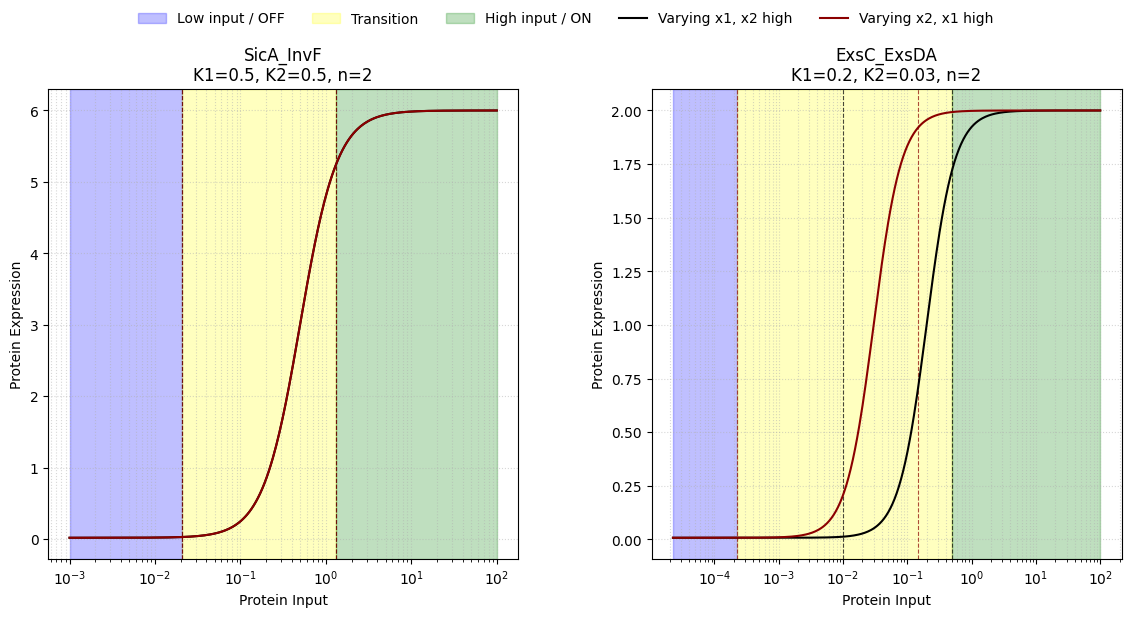

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# for the AND graphs
    # ON is defined by: (x1 > IH1 AND x2 > IH2)
    # OFF is defined by: (x1 < IL1 OR x2 < IL2)
    # transition is defined by: (IL < x < IH) for the inputs
    # the AND csv has no IL/IH, so we compute them from the SLOPE of the curve:
    #   IL = x where the slope rises through 1 (flat OFF zone -> steep transition zone)
    #   IH = x where the slope falls back through 1 (steep transition zone -> flat ON zone)
    # if both x1 and x2 -> 0, the output is (ymin) low
    # if both x1 and x2 -> infinity, the output is (ymax) high
# the AND gate equation: ymin + (ymax-ymin) * (x1^n / (K1^n + x1^n)) * (x2^n / (K2^n + x2^n))
#if slope is linear: transition region 



def slope_thresholds(K, n, ymin, ymax):
    A = ymax - ymin
    x = np.logspace(np.log10(K) - 6, np.log10(K) + 6, 200_001)   # fine log-spaced grid around K
    steep = A * n * K**n * x**(n - 1) / (K**n + x**n) ** 2 > 1    # True where slope > 1
    edges = np.flatnonzero(np.diff(steep.astype(int)))            # indices where it flips
    if len(edges) < 2:
        raise ValueError(f"slope never exceeds 1 (K={K}, n={n}, ymin={ymin}, ymax={ymax})")
    return x[edges[0] + 1], x[edges[-1]]     # first flip = IL, last flip = IH


file = pd.read_csv("parsed_Eco3C3G3T3.csv")
file = file[file["type"] == "AND"].reset_index(drop=True)
if file.empty:
    raise ValueError("The CSV contains no AND gates to plot.")

fig, axes = plt.subplots(1, len(file), figsize=(6 * len(file), 6), squeeze=False)

for index, row in file.iterrows():
    axis = axes.flat[index]
    ymin, ymax = row["ymin"], row["ymax"]
    k1, k2, n = row["K1"], row["K2"], row["n"]

    # slope-based thresholds for each input
    il1, ih1 = slope_thresholds(k1, n, ymin, ymax)
    il2, ih2 = slope_thresholds(k2, n, ymin, ymax)

    # one shaded band covering both inputs' transition zones
    transition_min = min(il1, il2)
    transition_max = max(ih1, ih2)

    # x range per gate, wide enough to include the thresholds
    x = np.logspace(np.log10(min(1e-3, transition_min / 10)),
                    np.log10(max(1e2, transition_max * 10)), 400)

    axis.axvspan(x.min(), transition_min, color="blue", alpha=0.25,
                 label="Low input / OFF" if index == 0 else None)
    axis.axvspan(transition_min, transition_max, color="yellow", alpha=0.25,
                 label="Transition" if index == 0 else None)
    axis.axvspan(transition_max, x.max(), color="green", alpha=0.25,
                 label="High input / ON" if index == 0 else None)

    # dashed lines at each input's own IL / IH (black = x1, red = x2)
    for val, color in ((il1, "black"), (ih1, "black"), (il2, "darkred"), (ih2, "darkred")):
        axis.axvline(val, color=color, linestyle="--", linewidth=0.8, alpha=0.7)

    # each input's curve with the other input fully on
    y_x1 = ymin + (ymax - ymin) * (x**n / (k1**n + x**n))
    y_x2 = ymin + (ymax - ymin) * (x**n / (k2**n + x**n))
    axis.plot(x, y_x1, color="black", linewidth=1.5, label="Varying x1, x2 high", zorder=2)
    axis.plot(x, y_x2, color="darkred", linewidth=1.5, label="Varying x2, x1 high", zorder=2)

    axis.set_xscale("log")
    axis.set_box_aspect(1)
    axis.set_title(f"{row['name']}\nK1={k1}, K2={k2}, n={n}")
    axis.set_xlabel("Protein Input")
    axis.set_ylabel("Protein Expression")
    axis.grid(True, which="both", linestyle=":", alpha=0.5)
    print(row["name"], f"x1: IL={il1:.4g} IH={ih1:.4g} | x2: IL={il2:.4g} IH={ih2:.4g}")

fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="upper center", ncol=5, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()